(768, 9)
Outcome
0    500
1    268
Name: count, dtype: int64 

Best SVM: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best Tree: {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 10} 

                 Train Acc  Test Acc  Precision  Recall     F1    Gap
Model                                                                
SVM (default)        0.840     0.740      0.652   0.556  0.600  0.100
SVM (tuned)          0.782     0.708      0.605   0.481  0.536  0.074
Tree (unpruned)      1.000     0.682      0.553   0.481  0.515  0.318
Tree (depth=3)       0.769     0.688      0.636   0.259  0.368  0.080
Tree (tuned)         0.761     0.695      0.652   0.278  0.390  0.066 

SVM (tuned)
              precision    recall  f1-score   support

 No Diabetes       0.75      0.83      0.79       100
    Diabetes       0.60      0.48      0.54        54

    accuracy                           0.71       154
   macro avg       0.68      0.66   

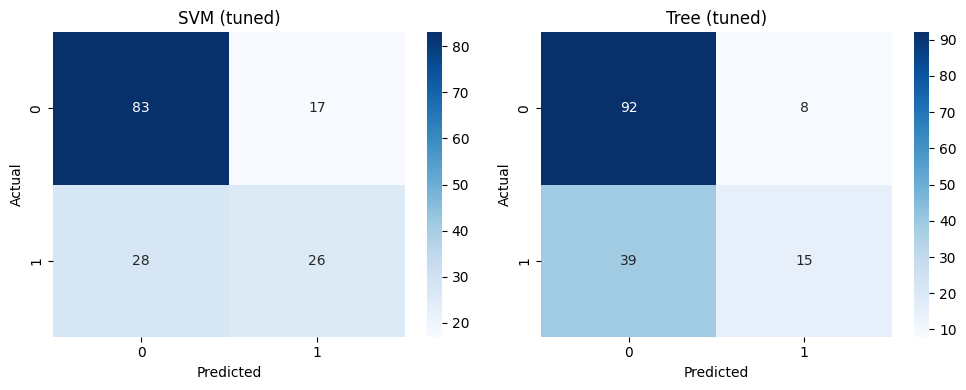

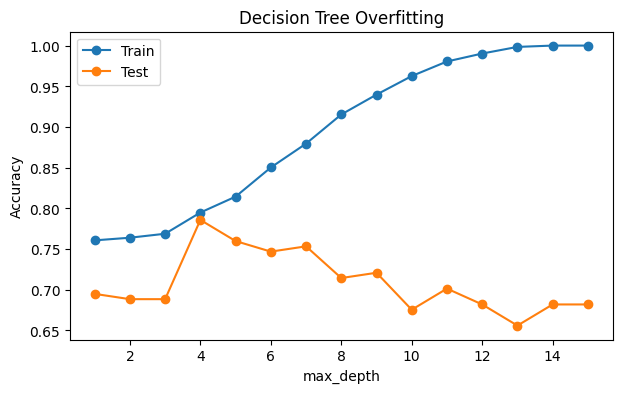

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42

# 1. Dataset load karna
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
df = pd.read_csv(url, header=None, names=cols)
print(df.shape)
print(df["Outcome"].value_counts(), "\n")

# 2. Missing values: in columns mein 0 asal mein missing hai
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_cols] = df[zero_cols].replace(0, np.nan)

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# 3. Train/Test split (80/20), imputation aur scaling se pehle taake leakage na ho
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)


def make_pipe(model):
    # Missing values median se fill, phir normalization, phir model
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])


# 4. Models train karna
svm = make_pipe(SVC(kernel="rbf", random_state=SEED)).fit(X_train, y_train)
dt = make_pipe(DecisionTreeClassifier(random_state=SEED)).fit(X_train, y_train)      # unpruned
dt_pruned = make_pipe(DecisionTreeClassifier(max_depth=3, random_state=SEED)).fit(X_train, y_train)

# 5. Hyperparameter tuning (GridSearch)
svm_grid = GridSearchCV(
    make_pipe(SVC(random_state=SEED)),
    {"model__C": [0.1, 1, 10, 100],
     "model__gamma": ["scale", 0.01, 0.1],
     "model__kernel": ["rbf", "linear"]},
    cv=5, n_jobs=-1).fit(X_train, y_train)

dt_grid = GridSearchCV(
    make_pipe(DecisionTreeClassifier(random_state=SEED)),
    {"model__max_depth": [2, 3, 4, 5, 6, 8],
     "model__min_samples_leaf": [1, 5, 10, 20],
     "model__criterion": ["gini", "entropy"]},
    cv=5, n_jobs=-1).fit(X_train, y_train)

print("Best SVM:", svm_grid.best_params_)
print("Best Tree:", dt_grid.best_params_, "\n")

# 6. Models ka comparison
models = {
    "SVM (default)": svm,
    "SVM (tuned)": svm_grid.best_estimator_,
    "Tree (unpruned)": dt,
    "Tree (depth=3)": dt_pruned,
    "Tree (tuned)": dt_grid.best_estimator_,
}

rows, preds = [], {}
for name, m in models.items():
    tr, te = m.predict(X_train), m.predict(X_test)
    preds[name] = te
    rows.append({
        "Model": name,
        "Train Acc": accuracy_score(y_train, tr),
        "Test Acc": accuracy_score(y_test, te),
        "Precision": precision_score(y_test, te),
        "Recall": recall_score(y_test, te),
        "F1": f1_score(y_test, te),
        "Gap": accuracy_score(y_train, tr) - accuracy_score(y_test, te),  # overfitting ka andaza
    })

print(pd.DataFrame(rows).set_index("Model").round(3), "\n")

for name in ["SVM (tuned)", "Tree (tuned)"]:
    print(name)
    print(classification_report(y_test, preds[name], target_names=["No Diabetes", "Diabetes"]))

# 7. Cross validation
for name, m in [("SVM", svm_grid.best_estimator_), ("Tree", dt_grid.best_estimator_)]:
    s = cross_val_score(m, X, y, cv=5)
    print(f"{name} 5-fold CV: {s.mean():.3f} (+/- {s.std():.3f})")

# 8. Confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["SVM (tuned)", "Tree (tuned)"]):
    sns.heatmap(confusion_matrix(y_test, preds[name]), annot=True, fmt="d",
                cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# 9. Overfitting graph: depth badhne par train vs test accuracy
depths = range(1, 16)
tr_acc, te_acc = [], []
for d in depths:
    m = make_pipe(DecisionTreeClassifier(max_depth=d, random_state=SEED)).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train))
    te_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr_acc, marker="o", label="Train")
plt.plot(depths, te_acc, marker="o", label="Test")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Overfitting")
plt.legend()
plt.show()